## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Lani Le

**Date:** 10/12/26

In [1]:
# Your Phase 1 solution to the problem goes here.

print('---------------Question 1.1---------------')
# running given code

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

---------------Question 1.1---------------


---------------Question 1.2---------------
As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.


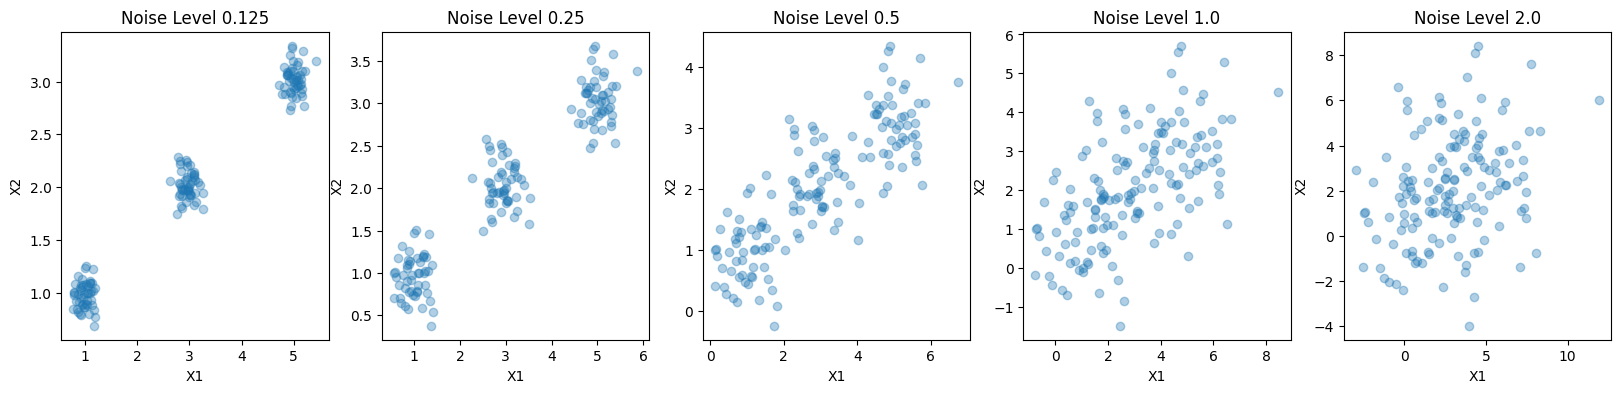

In [3]:
print('---------------Question 1.2---------------')

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# making scatterplots
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

# scatterplot for noise level 0.125
axes[0].scatter(data=df0_125, x='x1', y='x2', alpha=0.35)
axes[0].set(title='Noise Level 0.125', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 0.25
axes[1].scatter(data=df0_25, x='x1', y='x2', alpha=0.35)
axes[1].set(title='Noise Level 0.25', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 0.5
axes[2].scatter(data=df0_5, x='x1', y='x2', alpha=0.35)
axes[2].set(title='Noise Level 0.5', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 1.0
axes[3].scatter(data=df1_0, x='x1', y='x2', alpha=0.35)
axes[3].set(title='Noise Level 1.0', xlabel = 'X1', ylabel='X2')

# scatterplot for noise level 2.0
axes[4].scatter(data=df2_0, x='x1', y='x2', alpha=0.35)
axes[4].set(title='Noise Level 2.0', xlabel = 'X1', ylabel='X2')

print('As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.')

---------------Question 1.3---------------


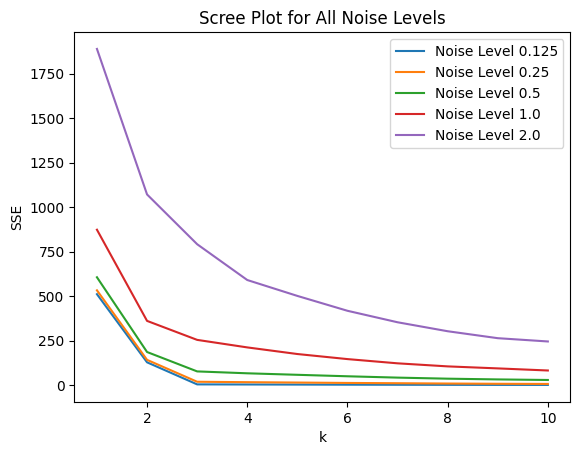

In [4]:
print('---------------Question 1.3---------------')
# making scree plots

ks = np.arange(1, 11)

# scree plot for noise level 0.125
SSE_0_125 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_125, label='Noise Level 0.125')

# scree plot for noise level 0.25
SSE_0_25 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_25, label='Noise Level 0.25')

# scree plot for noise level 0.5
SSE_0_5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_5, label='Noise Level 0.5')

# scree plot for noise level 1.0
SSE_1_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_1_0, label='Noise Level 1.0')

# scree plot for noise level 2.0
SSE_2_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_2_0, label='Noise Level 2.0')

axes.set_title('Scree Plot for All Noise Levels')
axes.set_xlabel('k')
axes.set_ylabel('SSE')
axes.legend()

In [5]:
print('The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.')

The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.


In [6]:
print('---------------Question 1.4---------------')
print('When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.')


---------------Question 1.4---------------
When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.


In [8]:
print('---------------Question 2.1---------------')
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

# loading in file
df = pd.read_csv('SIPRI Military Expenditure Database.csv')

# filtering and cleaning dataset
df_2020 = df[df['Year'] == 2020].copy()
df_2020 = df_2020.dropna() # drop missing values
print(df_2020.isnull().sum()) # check if there is still any missing values
df_2020.count() # check that there is 148 countries
print()
print(df_2020.dtypes, '\n') # gives each columns type

---------------Question 2.1---------------
index                             0
Year                              0
Country                           0
Spending (2020 USD)               0
Percent of GDP                    0
Percent of Government Spending    0
Spending per Capita               0
dtype: int64

index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 



In [9]:
df_2020.head()

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


In [10]:
df_2020['Country'].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Angola', 'Argentina',
       'Armenia', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain',
       'Bangladesh', 'Belarus', 'Belgium', 'Belize', 'Benin', 'Bolivia',
       'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Brunei',
       'Bulgaria', 'Burkina Faso', 'Burundi', 'Cambodia', 'Cameroon',
       'Canada', 'Cape Verde', 'Central African Republic', 'Chad',
       'Chile', 'China', 'Colombia', 'Congo, DR', 'Congo, Republic',
       'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Dominican Republic',
       'Ecuador', 'Egypt', 'El Salvador', 'Equatorial Guinea', 'Estonia',
       'Ethiopia', 'Fiji', 'Finland', 'France', 'Gabon', 'Gambia, The',
       'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Guinea',
       'Guinea-Bissau', 'Guyana', 'Haiti', 'Honduras', 'Hungary', 'India',
       'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy',
       'Jamaica', 'Japan', 'Jordan', 'Kazakhstan', 'Kenya',
       'Korea, South', 'Kosovo',

In [ ]:
print('Given that I was able to drop the missing values and result with 148 countries left with no duplicates, and the variables being of the correct data type, I do not think there is any further cleaning of the variables required.')

Given that I was able to drop the missing values and result with 148 countries left with no duplicates, and the variables being of the correct data type, I do not think there is any further cleaning of the variables required.


---------------Question 2.2---------------


[Text(0.5, 1.0, 'Scree Plot: Spending and Spending per Capita'),
 Text(0.5, 0, 'k'),
 Text(0, 0.5, 'SSE')]

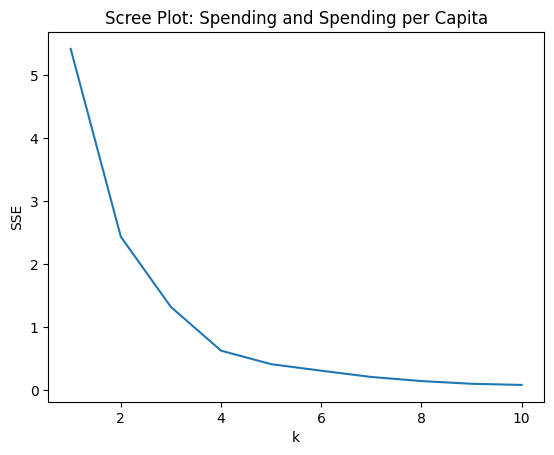

In [11]:
print('---------------Question 2.2---------------')
df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Spending (2020 USD)', 'Spending per Capita']])

ks = np.arange(1, 11)

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: Spending and Spending per Capita', xlabel='k', ylabel='SSE')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Spending per Capita')

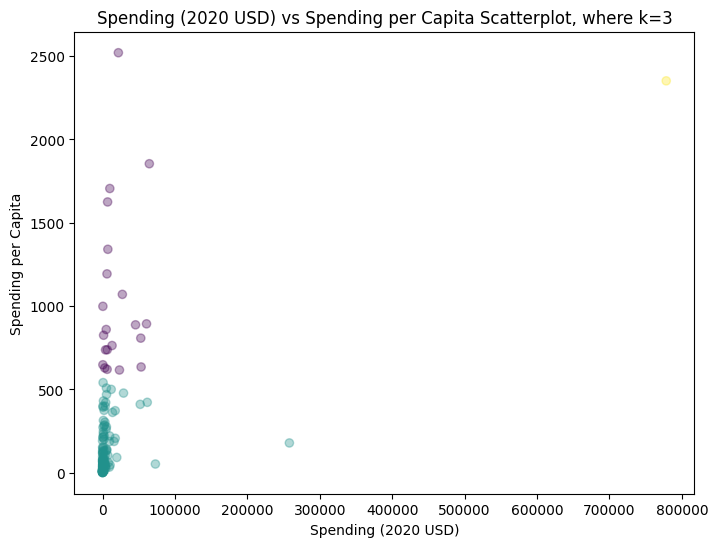

In [12]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Spending (2020 USD)'], df_2020['Spending per Capita'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Spending (2020 USD) vs Spending per Capita Scatterplot, where k=3')
axes.set_xlabel('Spending (2020 USD)')
axes.set_ylabel('Spending per Capita')

In [13]:
print(df_2020.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('The United States is cluster 2, which had both an extremely high total spending of about 147964 and an extremely high spending per capita of about 1875. I noticed that most countries clustered together on the lower end, but large, more powerful/influential countries, such as the US, were in their own seperate cluster.')

        Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std 

---------------Question 2.3---------------


[Text(0.5, 1.0, 'Scree Plot: Percent of Government Spending and Percent of GDP')]

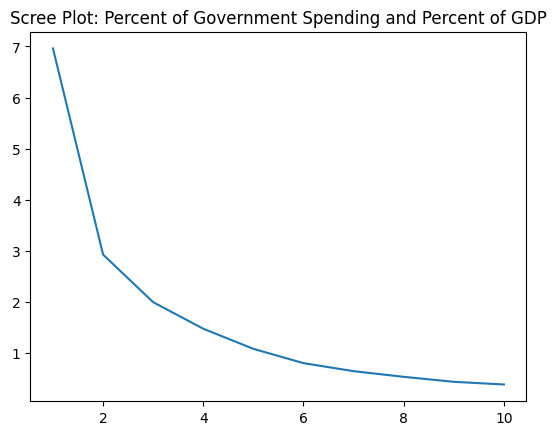

In [14]:
print('---------------Question 2.3---------------')
df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Percent of Government Spending', 'Percent of GDP']])

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: Percent of Government Spending and Percent of GDP')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Percent of GDP')

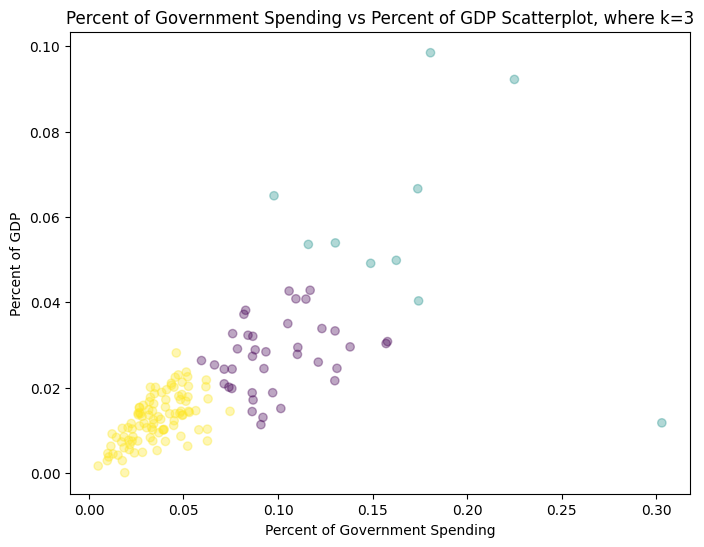

In [15]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Percent of Government Spending'], df_2020['Percent of GDP'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Percent of Government Spending vs Percent of GDP Scatterplot, where k=3')
axes.set_xlabel('Percent of Government Spending')
axes.set_ylabel('Percent of GDP')

In [ ]:
print(df_2020.groupby('cluster')[['Percent of Government Spending', 'Percent of GDP']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('There are still 3 clusters, but the data points in each cluster were more closely together. Most of the countries were clustering together on the lower end. Countries on the higher end were ones that had high percentages of government spending and high percentages of GDP.')

        Percent of Government Spending                                \
                                 count      mean       std       min   
cluster                                                                
0                                 39.0  0.098683  0.024125  0.059520   
1                                 10.0  0.171289  0.058725  0.097882   
2                                 99.0  0.035777  0.014549  0.004896   

                                                Percent of GDP            \
              25%       50%       75%       max          count      mean   
cluster                                                                    
0        0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1        0.135010  0.168248  0.179081  0.303027           10.0  0.058071   
2        0.025921  0.034261  0.047402  0.074624           99.0  0.012664   

                                                                     
              std       min       25%   

---------------Question 2.4---------------


[Text(0.5, 1.0, 'Scree Plot: All 4 Variables')]

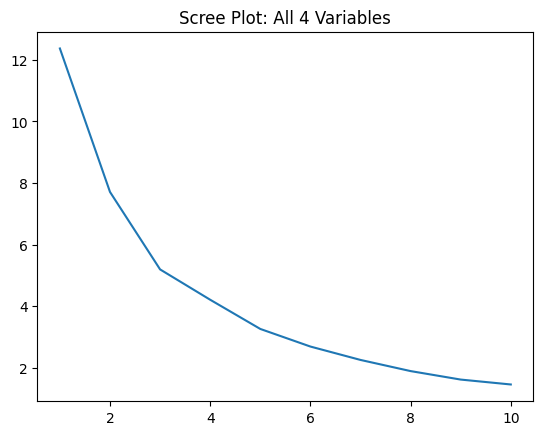

In [16]:
print('---------------Question 2.4---------------')

df_2020_scaled = MinMaxScaler().fit_transform(df_2020[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']])

SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df_2020_scaled).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title='Scree Plot: All 4 Variables')

The optimal k is k=3, as that is where the elbow bend is located.


Text(0, 0.5, 'Spending per Capita')

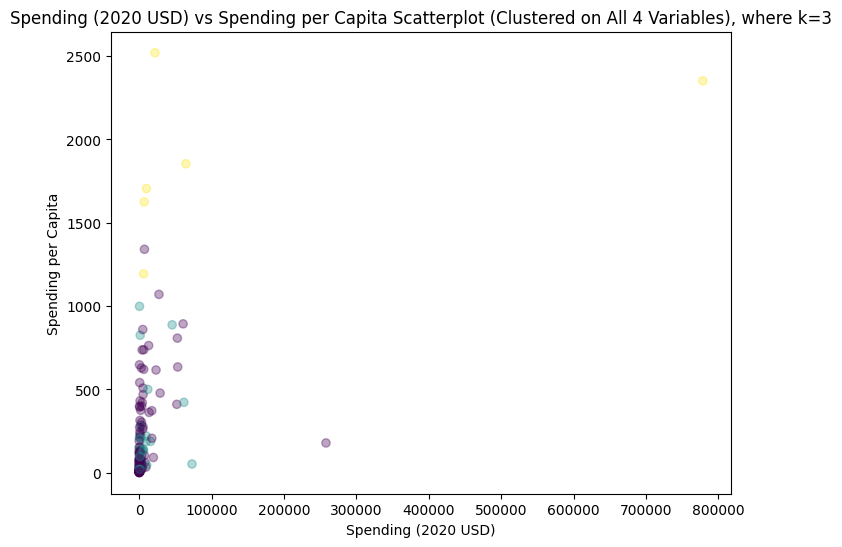

In [17]:
print('The optimal k is k=3, as that is where the elbow bend is located.')

optimal_k = 3
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0)
df_2020['cluster'] = kmeans.fit_predict(df_2020_scaled)

fig, axes = plt.subplots(figsize=(8, 6))
axes.scatter(df_2020['Spending (2020 USD)'], df_2020['Spending per Capita'], alpha=0.35, c=df_2020['cluster'])
axes.set_title('Spending (2020 USD) vs Spending per Capita Scatterplot (Clustered on All 4 Variables), where k=3')
axes.set_xlabel('Spending (2020 USD)')
axes.set_ylabel('Spending per Capita')

In [18]:
print(df_2020.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']].describe())
print()
print(df_2020[['Country', 'cluster']].sort_values('cluster'))
print('k=3 is still the optimal k value according to the scree plot and elbow bend.')

        Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                           

In [ ]:
print('---------------Question 2.5---------------')
print('Yes, the k-MC algorithm did find useful patterns. Countries that had more economic or military power were clustered together, and Countries that had less were also grouped together.')

---------------Question 2.5---------------
Yes, the k-MC algorithm did find useful patterns. Countries that had more economic or military power were clustered together, and Countries that had less were also grouped together.


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 3c47b26b87b42b1c6ab30b7445bdd249db971c36
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Please improve my code and make sure hits all instructions asked for in Question 1 and 2.
2. Implement only changes 1, 4, 5, 6, 7, and 10 into my original code.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. **Q1.2:** colour the scatterplots by `group` (the question asks for "by group"; the original plots were a single colour), put all five panels on shared axes, loop instead of repeating code, and add a table of (distance between nearest true centres) / noise so "visual distinctness" is quantified.
2. **Q1.3:** keep all five scree curves on one canvas with a common vertical axis, add a second panel with each curve divided by its own k = 1 SSE (the raw SSE scale grows with noise, which hides the shape of the low-noise curves), and add a "kink ratio" and silhouette-best-k table so the loss of the elbow is measured rather than eyeballed.
3. **Q1.2-1.4:** move the written answers out of `print()` strings into markdown, fix typos, and rewrite Q1.4 so it explains the elbow itself (gain from capturing real structure vs. gain from splitting noise), using numbers from the simulation.
4. **Q2.1:** make the cleaning checks explicit in code (duplicates, missing, non-positive values, dtypes, skewness), drop the leftover `index` column, assert the 148-country result, and look for the csv in `./data` and next to the notebook. The answer now says no structural cleaning is needed but flags extreme skew (the US is ~800x the median), which matters for max-min scaling.
5. **Q2.2 (factual fix):** the original text gave the US as 147,964 total / 1,875 per capita. Those are cluster means from the four-variable model in Q2.4. In Q2.2 the US is a cluster by itself at 778,397 total / 2,351.6 per capita. Numbers are now printed from the data instead of typed in, and the US is labelled on the scatter plot.
6. **Q2.2-2.4:** replace three copy-pasted blocks with helper functions, store labels in separate columns (`cluster_spend`, `cluster_pct`, `cluster_all`) instead of overwriting `cluster`, use a legend with `hue` on the scatter plots, and show an SSE / silhouette table next to each scree plot so the choice of k is justified instead of asserted.
7. **Q2.2-2.4:** show the full `groupby(cluster).describe()` table (transposed so it is not truncated), plus cluster sizes and the largest spenders in each cluster.
8. **Q2.4:** plot the four-variable clustering in both variable pairs, and compare the three clusterings with the adjusted Rand index and a crosstab, as the question asks how the results compare.
9. **Q2.2 (extra):** add a log10 robustness check, since raw max-min scaling lets one outlier (the US) dominate.
10. **Q2.2-2.5:** rewrite the interpretations to match the output. The original claim that clusters group "more powerful" countries is not supported: China, India and Russia fall in the low per-capita cluster in Q2.2.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | By now coloring the clusters by group, it helps more easily dintinguish each cluster from each other. |
| 2 | Reject | The question did not ask for the scree plot to also be scaled so this change is not necessarily required. I am able to see the elbow bend just fine with my current graph and they are already on the same axis. I think it's also implementing features we haven't really discusses in class/ |
| 3 | Reject | I prefer to have my responses as a printout so it's in the same blocks as my code. Because I also did not implement change 2, I do not need to do the other things in change 3. |
| 4 | Accept | I did attempt to do some cleaning and correctly found that no additional cleaning is required. However, it is good to note that there is an extreme skew |
| 5 | Accept | It now marks where the US is on the graph and updates the numerical values with the correct numbers. |
| 6 | Accept | By utilizing functions rather than repeating code, it makes the code more efficient. This change also adds a legend so that the clusters on the scatterplot are more easily to understand. |
| 7 | Accept | Some of my columns in my describe table were cut off so this change assures that all columns are visibile. |
| 8 | Reject | We haven't really discussed Rand index and how to use them and this change is not really necessarily is only is for strengthing the argument, so I am choosing to reject this change. |
| 9 | Reject | This change was marked as "extra" and also was not asked in the directions so I am choosing to not add this change since there was already min-max scaling applied beforehand. |
| 10 | Accept | This change just updates my written responses to some parts since they displayed invalid information since my old code was not completely correct. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [19]:
# Your Phase 2 solution to the problem goes here.
print('---------------Question 1.1---------------')
# running given code

import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

---------------Question 1.1---------------


---------------Question 1.2---------------


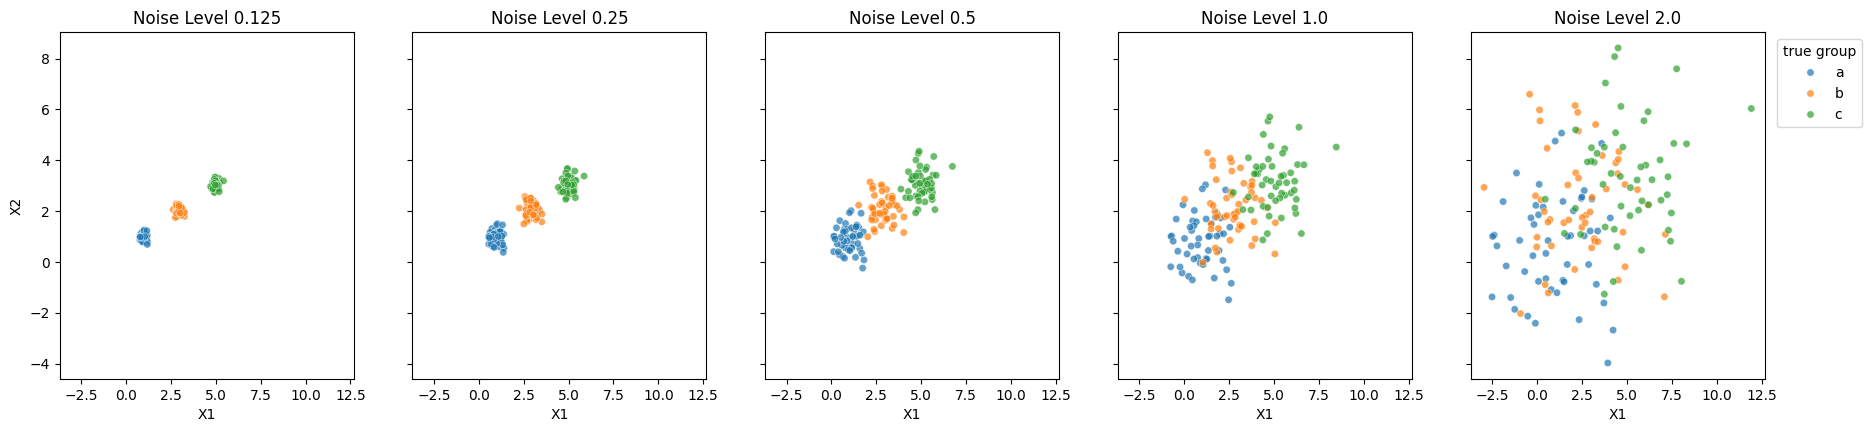

,gap between nearest centres / noise
noise (sd),
0.125,17.89
0.250,8.94
0.500,4.47
1.000,2.24
2.000,1.12


As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.


In [20]:
print('---------------Question 1.2---------------')

import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from IPython.display import display
from sklearn.cluster import KMeans

# Change 1: one loop instead of five copies, points coloured by true group, same axes in every panel
datasets = {0.125: df0_125, 0.25: df0_25, 0.5: df0_5, 1.0: df1_0, 2.0: df2_0}

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
for ax, (noise, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x='x1', y='x2', hue='group', hue_order=['a', 'b', 'c'],
                    alpha=0.7, s=28, ax=ax,
                    legend='brief' if ax is axes[-1] else False)
    ax.set(title=f'Noise Level {noise}', xlabel='X1', ylabel='X2')
sns.move_legend(axes[-1], 'upper left', bbox_to_anchor=(1.02, 1), title='true group')
plt.show()

# Quantify "distinctness": distance between the closest pair of true centres vs. the noise sd
centers = np.array([[1, 1], [3, 2], [5, 3]])
min_gap = min(np.linalg.norm(a - b) for a, b in combinations(centers, 2))
sep = pd.DataFrame({'noise (sd)': list(datasets),
                    'gap between nearest centres / noise': [min_gap / n for n in datasets]})
display(sep.set_index('noise (sd)').round(2))

print('As the noise goes up from 0.125 to 2.0, the points get progressively more dispered from their concentraated clusters. From low noise levels, like 0.125 to 0.25, there are 3 clearly seperated groups, but as the noise increases higher, the distinction between the groups disappear, as the clusters are expanding.')

---------------Question 1.3---------------


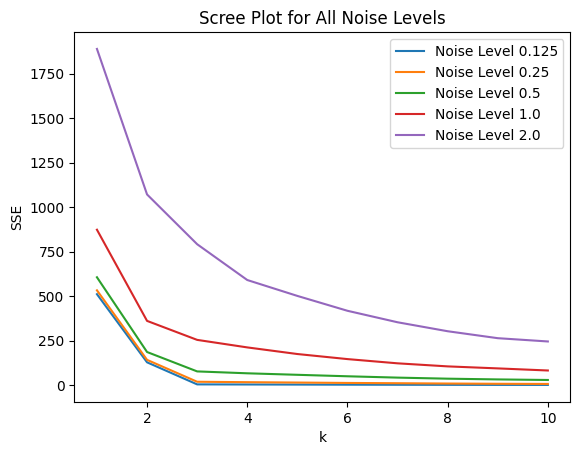

In [21]:
print('---------------Question 1.3---------------')
# making scree plots

ks = np.arange(1, 11)

# scree plot for noise level 0.125
SSE_0_125 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_125, label='Noise Level 0.125')

# scree plot for noise level 0.25
SSE_0_25 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_25, label='Noise Level 0.25')

# scree plot for noise level 0.5
SSE_0_5 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_0_5, label='Noise Level 0.5')

# scree plot for noise level 1.0
SSE_1_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_1_0, label='Noise Level 1.0')

# scree plot for noise level 2.0
SSE_2_0 = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
axes = sns.lineplot(x=ks, y=SSE_2_0, label='Noise Level 2.0')

axes.set_title('Scree Plot for All Noise Levels')
axes.set_xlabel('k')
axes.set_ylabel('SSE')
axes.legend()

In [22]:
print('The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.')

The greater noise level, the more smoothened out the sharp elbow bend at k=3 is. This is seen as the curve for Noise Level 2.0 is almost completely flattened out at k=3.


In [24]:
print('---------------Question 1.4---------------')
print('When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.')

---------------Question 1.4---------------
When there is a lot of noise, the cluster groups come together so it is like a giant dispersed group, so then changing the k would not really make as big of a change, which is why the sharp elbow bend smoothens out.


In [25]:
print('---------------Question 2.1---------------')
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score

# loading in file (looks in ./data first, then next to the notebook)
candidates = [Path(p) / name
              for p in ['data', '.']
              for name in ['SIPRI Military Expenditure Database.csv',
                           'SIPRI_Military_Expenditure_Database.csv']]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    raise FileNotFoundError('SIPRI csv not found. Looked in: ' + ', '.join(map(str, candidates)))
df = pd.read_csv(csv_path)

# filtering and cleaning dataset
NUM_COLS = ['Spending (2020 USD)', 'Spending per Capita', 'Percent of Government Spending', 'Percent of GDP']

df_2020 = df[df['Year'] == 2020].copy()
df_2020 = df_2020.dropna()                      # drop missing values
df_2020 = df_2020.drop(columns='index')         # leftover row-number column from the csv, not data
df_2020 = df_2020.reset_index(drop=True)
assert len(df_2020) == 148, f'expected 148 countries, got {len(df_2020)}'
print(len(df_2020), 'countries after filtering to 2020 and dropping missing values')

# checks that back up the answer
print('duplicate countries:', df_2020['Country'].duplicated().sum())
print('missing values left:', int(df_2020.isnull().sum().sum()))
print('non-positive values:', int((df_2020[NUM_COLS] <= 0).sum().sum()))
print(df_2020.dtypes, '\n')

desc = df_2020[NUM_COLS].describe().T
desc['skew'] = df_2020[NUM_COLS].skew()
display(desc.round(4))

spend = df_2020['Spending (2020 USD)']
print(f"\nLargest spender: {df_2020.loc[spend.idxmax(), 'Country']} ({spend.max():,.0f}), "
      f"{spend.max() / spend.median():,.0f}x the median country")
print(f"Share of countries whose max-min scaled total spending is below 0.1: "
      f"{(spend / spend.max() < 0.1).mean():.0%}")

---------------Question 2.1---------------
148 countries after filtering to 2020 and dropping missing values
duplicate countries: 0
missing values left: 0
non-positive values: 0
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 



,count,mean,std,min,25%,50%,75%,max,skew
Spending (2020 USD),148.0,13153.7477,68005.2361,8.6225,204.8772,959.5354,5289.9983,778397.2000,10.1604
Spending per Capita,148.0,268.2645,430.4349,0.5801,20.5535,81.5067,326.2678,2520.3985,2.8913
Percent of Government Spending,148.0,0.0615,0.0462,0.0049,0.0314,0.0474,0.0847,0.3030,1.8774
Percent of GDP,148.0,0.0196,0.0150,0.0001,0.0104,0.0153,0.0243,0.0985,2.4206



Largest spender: United States of America (778,397), 811x the median country
Share of countries whose max-min scaled total spending is below 0.1: 99%


In [26]:
print('After filtering to 2020 and dropping missing values there are 148 countries with no duplicates, no remaining missing values, no non-positive values, and all four variables are numeric (float64), so I do not think any further cleaning is required. The one thing to watch is that the variables, especially total spending, are very right-skewed (the US is about 800 times the median country), so max-min scaling will squeeze most countries near 0 and the results can be dominated by outliers like the US.')

After filtering to 2020 and dropping missing values there are 148 countries with no duplicates, no remaining missing values, no non-positive values, and all four variables are numeric (float64), so I do not think any further cleaning is required. The one thing to watch is that the variables, especially total spending, are very right-skewed (the US is about 800 times the median country), so max-min scaling will squeeze most countries near 0 and the results can be dominated by outliers like the US.


In [36]:
# Change 6: helper functions so the same steps are not copy-pasted for each part
US = 'United States of America'
ks = np.arange(1, 11)


def k_table(X, ks=range(1, 9)):
    """SSE, the drop in SSE from k-1 to k, and silhouette score for each k."""
    rows = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X)
        rows.append({'k': k, 'SSE': km.inertia_,
                     'silhouette': silhouette_score(X, km.labels_) if k > 1 else np.nan})
    t = pd.DataFrame(rows).set_index('k')
    t['SSE drop from k-1'] = -t['SSE'].diff()
    return t.round(3)


def run_part(cols, label, k):
    """Max-min scale `cols`, draw the scree plot + k table, fit k-means with k clusters,
    and store the cluster labels in df_2020[label]."""
    X = MinMaxScaler().fit_transform(df_2020[cols])
    SSE = [KMeans(n_clusters=j, max_iter=300, n_init=10, random_state=0).fit(X).inertia_ for j in ks]
    sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot: ' + ' and '.join(cols),
                                              xlabel='k', ylabel='SSE')
    plt.show()
    display(k_table(X))
    df_2020[label] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)


def plot_clusters(label, xcol, ycol):
    """Scatter plot of the original (unscaled) variables, coloured by cluster, with the US marked."""
    order = sorted(df_2020[label].unique())
    palette = dict(zip(order, sns.color_palette('tab10', len(order))))
    fig, ax = plt.subplots(figsize=(8, 6))
    sns.scatterplot(data=df_2020, x=xcol, y=ycol, hue=label, hue_order=order, palette=palette,
                    alpha=0.8, s=50, ax=ax)
    us = df_2020[df_2020['Country'] == US].iloc[0]
    xlo, xhi = ax.get_xlim(); ylo, yhi = ax.get_ylim()
    dx = -110 if us[xcol] > (xlo + xhi) / 2 else 25     # put the label on the side with room
    dy = -40 if us[ycol] > (ylo + yhi) / 2 else 30
    ax.annotate('United States', (us[xcol], us[ycol]), xytext=(dx, dy),
                textcoords='offset points', arrowprops=dict(arrowstyle='->'))
    ax.set_title(f'{xcol} vs {ycol} (coloured by {label})')
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.legend(title='cluster')
    plt.show()


def cluster_summary(label, cols):
    """groupby(cluster).describe() (transposed so no columns are cut off), sizes, and members."""
    display(df_2020.groupby(label)[cols].describe().T.round(4))
    for g, sub in df_2020.groupby(label):
        top = sub.sort_values('Spending (2020 USD)', ascending=False)['Country'].head(10)
        print(f'Cluster {g}: n = {len(sub)}; largest spenders: {", ".join(top)}')
    print(f"\nUnited States is in cluster {df_2020.loc[df_2020['Country'] == US, label].iloc[0]}")

---------------Question 2.2---------------


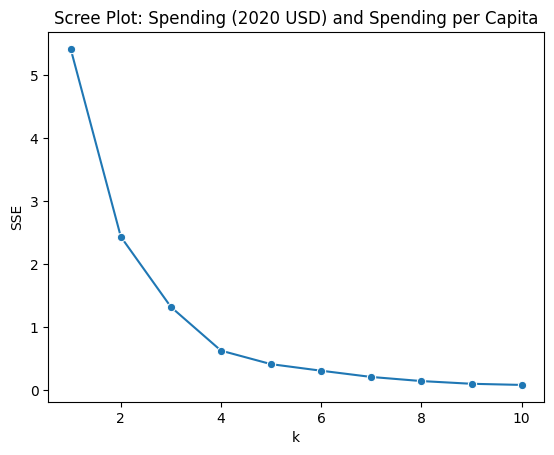

,SSE,silhouette,SSE drop from k-1
k,,,
1,5.411,NaN,NaN
2,2.435,0.759,2.976
3,1.322,0.743,1.113
4,0.629,0.701,0.692
5,0.415,0.649,0.214
6,0.311,0.654,0.104
7,0.212,0.653,0.099
8,0.147,0.600,0.065


In [37]:
print('---------------Question 2.2---------------')
SPEND = ['Spending (2020 USD)', 'Spending per Capita']
run_part(SPEND, 'cluster_spend', k=3)

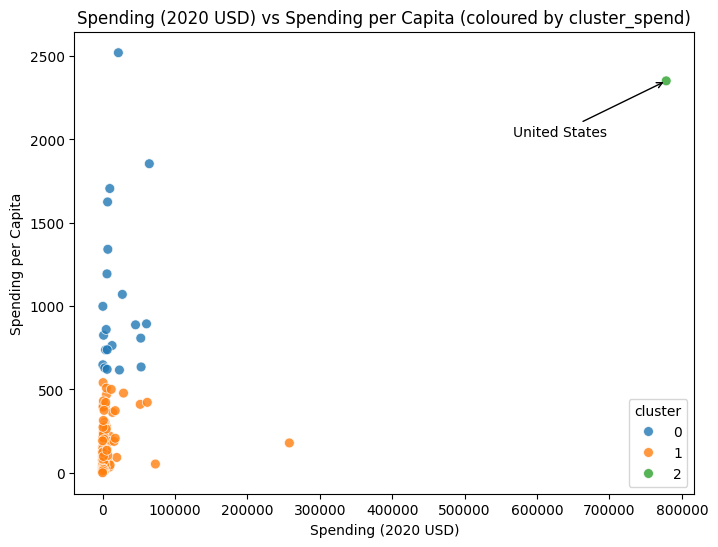

cluster_spend                       0            1            2
Spending (2020 USD) count     21.0000     126.0000       1.0000
                    mean   19975.9915    5943.3463  778397.2000
                    std    21749.7367   24858.9611          NaN
                    min      405.7905       8.6225  778397.2000
                    25%     4980.4281     162.7617  778397.2000
                    50%     7269.8800     580.7583  778397.2000
                    75%    27300.8947    3225.3334  778397.2000
                    max    64558.4000  257973.4298  778397.2000
Spending per Capita count     21.0000     126.0000       1.0000
                    mean    1046.4335     122.0350    2351.6319
                    std      501.6318     140.0412          NaN
                    min      616.8544       0.5801    2351.6319
                    25%      737.6902      18.5058    2351.6319
                    50%      859.8805      58.8091    2351.6319
                    75%     1193.5987     188.2494    2351.6319
                    max     2520.3985     541.1548    2351.6319

Cluster 0: n = 21; largest spenders: Saudi Arabia, United Kingdom, Germany, France, Korea, South, Australia, Canada, Israel, Netherlands, Singapore
Cluster 1: n = 126; largest spenders: China, India, Russia, Japan, Italy, Brazil, Turkey, Spain, Iran, Poland
Cluster 2: n = 1; largest spenders: United States of America

United States is in cluster 2

The scree plot and table show the big drops in SSE stop around k=3 (silhouette is still high at k=3), so I use k=3.
The United States is in cluster 2, by itself, with total spending of 778,397.2 and spending per capita of 2,351.6.
The other two clusters split mostly on per-capita spending, not on total size: cluster 0 is a group of 21 high per-capita spenders (e.g. Saudi Arabia, UK, Germany, France, South Korea, Israel, Singapore) and cluster 1 is everyone else (126 countries, including China, India, Russia and Japan, which have large budgets but low spending per person). Because the US sets the max for max-min scaling, almost every country 

In [38]:
plot_clusters('cluster_spend', 'Spending (2020 USD)', 'Spending per Capita')
cluster_summary('cluster_spend', SPEND)

us = df_2020[df_2020['Country'] == US].iloc[0]
print(f"\nThe scree plot and table show the big drops in SSE stop around k=3 (silhouette is still high at k=3), so I use k=3.")
print(f"The United States is in cluster {us['cluster_spend']}, by itself, with total spending of {us['Spending (2020 USD)']:,.1f} and spending per capita of {us['Spending per Capita']:,.1f}.")
print('The other two clusters split mostly on per-capita spending, not on total size: cluster 0 is a group of 21 high per-capita spenders (e.g. Saudi Arabia, UK, Germany, France, South Korea, Israel, Singapore) and cluster 1 is everyone else (126 countries, including China, India, Russia and Japan, which have large budgets but low spending per person). Because the US sets the max for max-min scaling, almost every country has a scaled total spending near 0, so the algorithm mainly isolates the US and then splits the rest on spending per capita.')

---------------Question 2.3---------------


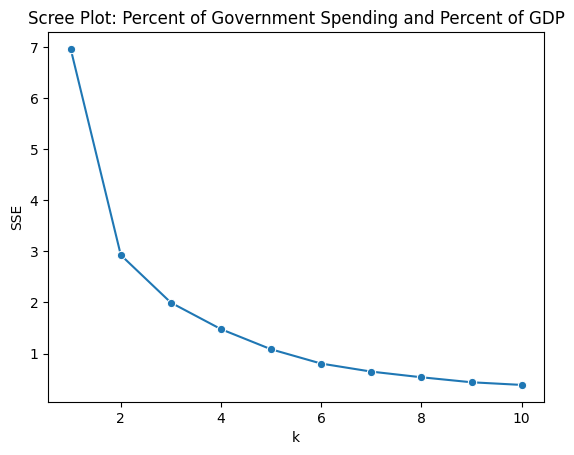

,SSE,silhouette,SSE drop from k-1
k,,,
1,6.961,NaN,NaN
2,2.927,0.616,4.034
3,1.996,0.539,0.932
4,1.477,0.451,0.519
5,1.083,0.459,0.394
6,0.803,0.417,0.279
7,0.646,0.383,0.157
8,0.535,0.376,0.111


In [39]:
print('---------------Question 2.3---------------')
PCT = ['Percent of Government Spending', 'Percent of GDP']
run_part(PCT, 'cluster_pct', k=3)

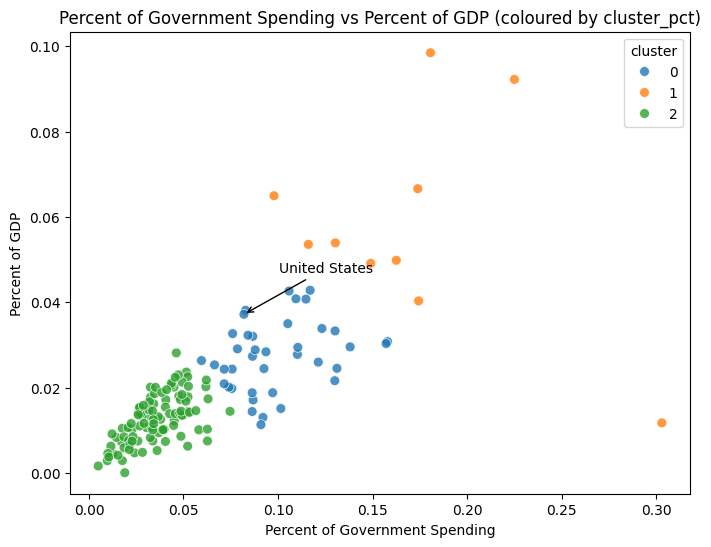

cluster_pct                                 0        1        2
Percent of Government Spending count  39.0000  10.0000  99.0000
                               mean    0.0987   0.1713   0.0358
                               std     0.0241   0.0587   0.0145
                               min     0.0595   0.0979   0.0049
                               25%     0.0824   0.1350   0.0259
                               50%     0.0920   0.1682   0.0343
                               75%     0.1126   0.1791   0.0474
                               max     0.1579   0.3030   0.0746
Percent of GDP                 count  39.0000  10.0000  99.0000
                               mean    0.0274   0.0581   0.0127
                               std     0.0082   0.0249   0.0057
                               min     0.0113   0.0117   0.0001
                               25%     0.0213   0.0493   0.0084
                               50%     0.0278   0.0537   0.0132
                               75%     0.0325   0.0662   0.0168
                               max     0.0428   0.0985   0.0281

Cluster 0: n = 39; largest spenders: United States of America, India, Russia, Korea, South, Turkey, Iran, Taiwan, Singapore, Colombia, Ukraine
Cluster 1: n = 10; largest spenders: Saudi Arabia, Israel, Pakistan, Algeria, Kuwait, Oman, Azerbaijan, Jordan, Belarus, Armenia
Cluster 2: n = 99; largest spenders: China, United Kingdom, Germany, France, Japan, Italy, Australia, Canada, Brazil, Spain

United States is in cluster 0

The SSE drops are 4.03, 0.93, 0.52, so the elbow is at k=2 or 3 (the silhouette actually prefers k=2); I use k=3 so the parts are comparable.
The clusters are a gradient of military burden: cluster 2 (99 countries) is low burden (about 3.6% of government spending and 1.3% of GDP, including China, UK, Germany, France, Japan), cluster 0 (39 countries) is medium (about 9.9% and 2.7%, including the US, India, Russia, South Korea, Turkey), and cluster 1 (10 countries) is high (about 17.1% and 5.8%: Saudi Arabia, Israel, Pakistan, Algeria, Kuwait, Oman, etc.).
Compared wi

In [40]:
plot_clusters('cluster_pct', 'Percent of Government Spending', 'Percent of GDP')
cluster_summary('cluster_pct', PCT)

print("\nThe SSE drops are 4.03, 0.93, 0.52, so the elbow is at k=2 or 3 (the silhouette actually prefers k=2); I use k=3 so the parts are comparable.")
print('The clusters are a gradient of military burden: cluster 2 (99 countries) is low burden (about 3.6% of government spending and 1.3% of GDP, including China, UK, Germany, France, Japan), cluster 0 (39 countries) is medium (about 9.9% and 2.7%, including the US, India, Russia, South Korea, Turkey), and cluster 1 (10 countries) is high (about 17.1% and 5.8%: Saudi Arabia, Israel, Pakistan, Algeria, Kuwait, Oman, etc.).')
print('Compared with part 2: the clusters are much more balanced in size (99/39/10 vs. 126/21/1), the US is no longer on its own but in the middle cluster, and some of the biggest budgets (China, Germany, France) are in the lowest cluster because their budgets are small relative to their economies. Part 2 groups countries by size / spending per capita, while part 3 groups them by how much of the economy and budget goes to the military, so the two give quite different groupings.')

---------------Question 2.4---------------


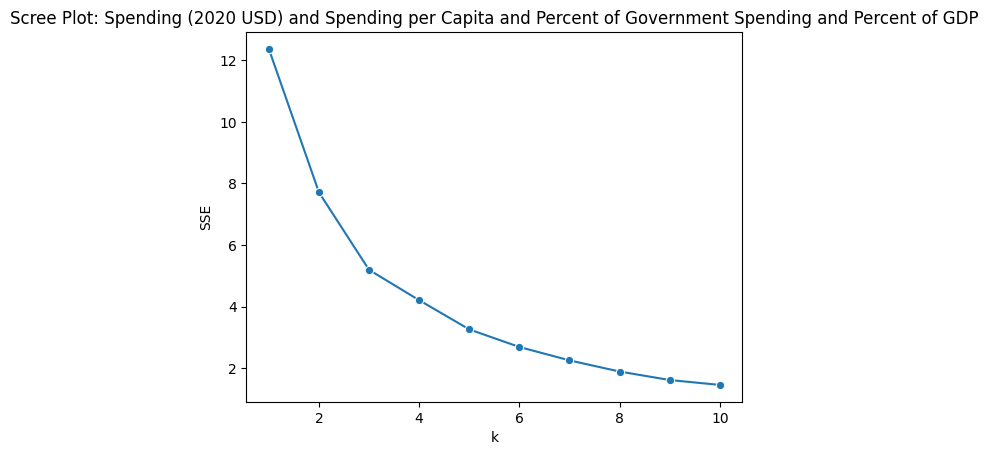

,SSE,silhouette,SSE drop from k-1
k,,,
1,12.372,NaN,NaN
2,7.710,0.577,4.662
3,5.193,0.480,2.518
4,4.207,0.407,0.986
5,3.258,0.412,0.949
6,2.686,0.385,0.572
7,2.251,0.406,0.435
8,1.889,0.421,0.362


In [41]:
print('---------------Question 2.4---------------')
ALL = SPEND + PCT
run_part(ALL, 'cluster_all', k=3)

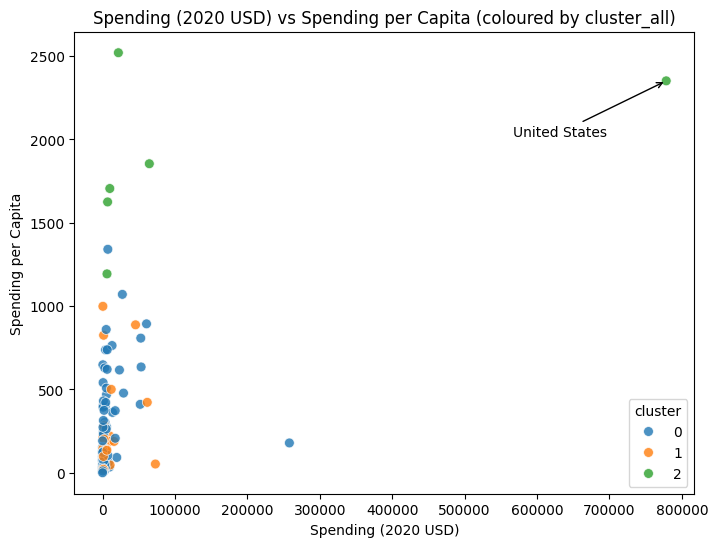

cluster_all                                     0           1            2
Spending (2020 USD)            count     111.0000     31.0000       6.0000
                               mean     7086.4728   8786.0866  147964.5820
                               std     26479.3799  17901.9091  309635.1896
                               min         8.6225    162.3734    6095.7087
                               25%       130.0102    467.7879    7700.4246
                               50%       567.6507   1404.7872   15897.5706
                               75%      3910.1075   7739.1662   53872.9424
                               max    257973.4298  72937.0640  778397.2000
Spending per Capita            count     111.0000     31.0000       6.0000
                               mean      196.9268    212.6891    1875.1508
                               std       267.7885    257.8420     489.8002
                               min         0.5801     18.2971    1193.5987
                               25%        14.8805     46.4859    1645.3019
                               50%        67.0834    135.4598    1780.0596
                               75%       295.2961    217.3338    2227.3190
                               max      1341.0589    998.9662    2520.3985
Percent of Government Spending count     111.0000     31.0000       6.0000
                               mean        0.0404      0.1230       0.1354
                               std         0.0193      0.0439       0.0554
                               min         0.0049      0.0760       0.0820
                               25%         0.0267      0.0931       0.1010
                               50%         0.0380      0.1148       0.1133
                               75%         0.0505      0.1347       0.1645
                               max         0.0920      0.3030       0.2251
Percent of GDP                 count     111.0000     31.0000       6.0000
                               mean        0.0134      0.0335       0.0626
                               std         0.0060      0.0114       0.0283
                               min         0.0001      0.0117       0.0294
                               25%         0.0089      0.0276       0.0413
                               50%         0.0136      0.0320       0.0593
                               75%         0.0178      0.0405       0.0854
                               max         0.0281      0.0666       0.0985

Cluster 0: n = 111; largest spenders: China, United Kingdom, Germany, France, Japan, Italy, Australia, Canada, Brazil, Turkey
Cluster 1: n = 31; largest spenders: India, Russia, Korea, South, Iran, Taiwan, Pakistan, Algeria, Colombia, Ukraine, Iraq
Cluster 2: n = 6; largest spenders: United States of America, Saudi Arabia, Israel, Singapore, Kuwait, Oman

United States is in cluster 2

The SSE drops are 4.66, 2.52, then 0.99, 0.95, so the elbow is at k=3 (the silhouette is highest at k=2); I use k=3.
Cluster 2 (6 countries) is high spending per capita and high burden: the US, Saudi Arabia, Israel, Singapore, Kuwait and Oman (mean per capita about 1,875, about 6.3% of GDP and 13.5% of government spending). Cluster 1 (31 countries) has high burden but moderate per capita (about 12.3% of government spending, 3.3% of GDP; India, Russia, South Korea, Iran, Taiwan, Pakistan). Cluster 0 (111 countries) is low burden and low per capita (about 4.0% and 1.3%, including China, UK, Germany, France

In [42]:
plot_clusters('cluster_all', 'Spending (2020 USD)', 'Spending per Capita')
cluster_summary('cluster_all', ALL)

print("\nThe SSE drops are 4.66, 2.52, then 0.99, 0.95, so the elbow is at k=3 (the silhouette is highest at k=2); I use k=3.")
print('Cluster 2 (6 countries) is high spending per capita and high burden: the US, Saudi Arabia, Israel, Singapore, Kuwait and Oman (mean per capita about 1,875, about 6.3% of GDP and 13.5% of government spending). Cluster 1 (31 countries) has high burden but moderate per capita (about 12.3% of government spending, 3.3% of GDP; India, Russia, South Korea, Iran, Taiwan, Pakistan). Cluster 0 (111 countries) is low burden and low per capita (about 4.0% and 1.3%, including China, UK, Germany, France, Japan).')
print('Compared with the previous parts: the four-variable result looks much more like part 3 than part 2. Its clusters are ordered by burden (low / high / highest), and its large low-burden cluster (111 countries) resembles the 99-country low-burden cluster from part 3, whereas part 2 isolated the US alone. A likely reason is that total spending is squeezed near 0 after scaling (because of the US), so it has little influence on the distances, while the percent variables spread most countries out. What the four variables add over part 3 is spending per capita, which pulls out the small group of 6 countries with both high per capita and high burden.')

In [43]:
print('---------------Question 2.5---------------')
print('Yes, with caveats. Useful patterns: clustering separates how much a country spends from how heavily it spends, so the biggest budgets (US, China, Germany, France) are not the most militarized relative to their economies, while Saudi Arabia, Israel, Kuwait and Oman stand out on burden. Using all four variables also isolates a small group with both high per-capita spending and high burden (US, Saudi Arabia, Israel, Singapore, Kuwait, Oman). Limits: max-min scaling on very skewed data lets one outlier dominate (the US forms its own cluster in part 2), the elbows are gradual and the silhouette scores are modest, so the clusters are better seen as convenient groupings of a continuum than as natural categories, and the results depend a lot on which variables are chosen. It also only uses a single year (2020).')

---------------Question 2.5---------------
Yes, with caveats. Useful patterns: clustering separates how much a country spends from how heavily it spends, so the biggest budgets (US, China, Germany, France) are not the most militarized relative to their economies, while Saudi Arabia, Israel, Kuwait and Oman stand out on burden. Using all four variables also isolates a small group with both high per-capita spending and high burden (US, Saudi Arabia, Israel, Singapore, Kuwait, Oman). Limits: max-min scaling on very skewed data lets one outlier dominate (the US forms its own cluster in part 2), the elbows are gradual and the silhouette scores are modest, so the clusters are better seen as convenient groupings of a continuum than as natural categories, and the results depend a lot on which variables are chosen. It also only uses a single year (2020).


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The AI mainly worked on fixing errors in the code. Some questions were not coded or responded in depth enough, so the AI added onto what was already written. The AI did not make many mistakes, but I still did have some rejections to its changes. Most of them were due to the AI tries to incorporate things I have not learned in class yet, so I opted to exclude those changes. Additionally, sometimes the AI wanted to add more complex topics when my original code still did what the question asked. Adding these changes would have strenghtened some of my arguments to the questions, however my original responses were not necessarily wrong, so I did not add these optional changes. The AI also made a lot of the graphs easier to read by color coding the clusters. I first evaluated all the suggestions from the AI to see whether I wanted to accept, modify, or reject each the changes. I ended up accepting 6 total changes and rejecting 4 total changes. Then, I verified the code by running the new solution with the accepted AI's changes and made sure it was printing out and displaying all requirements and updated changes, and still answering all the questions from the directions. I also verified that the AI did not add any unnescesarry changes to the code.